In [1]:
import torch
from torch_geometric.nn import MessagePassing
import matplotlib.pyplot as plt


class FVM_HodgkinHuxley(MessagePassing):
    def __init__(self):
        super().__init__(aggr='add')

    ## Internal class functions to define the alpha and beta functions
    @staticmethod
    def _rate_fractional(v, A, V_shift, K, eps):
        return A * (v + V_shift) / (1.0 - torch.exp(-(v + V_shift) / K) + eps)

    @staticmethod
    def _rate_exponential(v, A, V_shift, K):
        return A * torch.exp(-(v + V_shift) / K)

    @staticmethod
    def _rate_inverse_sigmoid(v, A, V_shift, K):
        return A / (1.0 + torch.exp(-(v + V_shift) / K))

    def forward(self, V, gating_vars, edge_index, g_axial, params, I_ext, dt):
        # Pass dt into propagate so update() can execute Rush-Larsen integration
        return self.propagate(
            edge_index, x=V, gating_vars=gating_vars,
            g_axial=g_axial, p=params, I_ext=I_ext, dt=dt
        )

    def message(self, x_j, g_axial):
        # Returns g_axial for each incoming edge so aggr_out sums the total
        # axial conductance connected to each node (2*g_axial in interior,
        # 1*g_axial at sealed boundaries, or k*g_axial at branch points)
        return torch.ones_like(x_j) * g_axial

    def update(self, aggr_out, x, gating_vars, p, I_ext, dt):
        # 1. Unpack the gating variables
        m, h, n = gating_vars.split(1, dim=1)

        # 2. Rush-Larsen exact exponential integration for m, h, n
        alpha_m = self._rate_fractional(x, *p['alpha_m'])
        beta_m  = self._rate_exponential(x, *p['beta_m'])
        m_inf = alpha_m / (alpha_m + beta_m)
        tau_m = 1.0 / (alpha_m + beta_m)
        m_new = m_inf + (m - m_inf) * torch.exp(-dt / tau_m)

        alpha_h = self._rate_exponential(x, *p['alpha_h'])
        beta_h  = self._rate_inverse_sigmoid(x, *p['beta_h'])
        h_inf = alpha_h / (alpha_h + beta_h)
        tau_h = 1.0 / (alpha_h + beta_h)
        h_new = h_inf + (h - h_inf) * torch.exp(-dt / tau_h)

        alpha_n = self._rate_fractional(x, *p['alpha_n'])
        beta_n  = self._rate_exponential(x, *p['beta_n'])
        n_inf = alpha_n / (alpha_n + beta_n)
        tau_n = 1.0 / (alpha_n + beta_n)
        n_new = n_inf + (n - n_inf) * torch.exp(-dt / tau_n)

        gating_vars_new = torch.cat([m_new, h_new, n_new], dim=1)

        # 3. Linearized ionic current terms (Eqs. 10-14 in Ashraf et al., 2026)
        g_Na_eff = p['g_Na'] * (m_new**3) * h_new
        g_K_eff  = p['g_K']  * (n_new**4)
        g_L_eff  = p['g_L']

        g_total  = g_Na_eff + g_K_eff + g_L_eff
        I_linear = (g_Na_eff * p['E_Na'] +
                    g_K_eff  * p['E_K']  +
                    g_L_eff  * p['E_L'])

        # 4. Construct diagonal (a_P) and right-hand side vector (b_P)
        # Note: aggr_out holds the sum of g_axial over all connected neighbors
        a_P = 1.0 + (dt / p['C_m']) * (aggr_out + g_total)
        b_P = x + (dt / p['C_m']) * (I_linear + I_ext)

        return a_P, b_P, gating_vars_new

c:\Users\Patrick\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
## Initialize the model and parameters (modern resting convention V_rest = -65 mV)
HH_PARAMS = {
    # Tuples ordered as: (A, V_shift, K, [eps])
    'alpha_m': (0.1, 40.0, 10.0, 1e-8),
    'beta_m':  (4.0, 65.0, 18.0),
    'alpha_h': (0.07, 65.0, 20.0),
    'beta_h':  (1.0, 35.0, 10.0),
    'alpha_n': (0.01, 55.0, 10.0, 1e-8),
    'beta_n':  (0.125, 65.0, 80.0),
    'g_Na': 120.0, 'E_Na': 50.0,
    'g_K': 36.0,   'E_K': -77.0,
    'g_L': 0.3,    'E_L': -54.387,
    'C_m': 1.0
}

# Simulation parameters:
dt = 0.01     # ms (unconditionally stable with semi-implicit step)
t_max = 40.0  # ms (matches paper duration)
steps = int(t_max / dt)

num_nodes = 100
axon_length = 1.0     # cm
dx = axon_length / num_nodes
axon_radius = 0.0238  # cm
Ri = 35.4             # ohm*cm

# Build the bidirectional graph
forward_edges = [[i, i+1] for i in range(num_nodes - 1)]
edges = forward_edges + [[dst, src] for src, dst in forward_edges]
edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()

# Axial conductance between compartments (converted from S/cm^2 to mS/cm^2)
g_axial = (axon_radius * 1000.0) / (2.0 * Ri * dx**2)

# Pre-build the constant off-diagonal axial matrix (a_W and a_E in Eq. 14)
A_off_diag = torch.zeros((num_nodes, num_nodes))
src, dst = edge_index
A_off_diag[dst, src] = -(dt / HH_PARAMS['C_m']) * g_axial

# Initialize solver and state tensors
FVM_HH_solver = FVM_HodgkinHuxley()

V = torch.full((num_nodes, 1), -65.0)
m = torch.full((num_nodes, 1), 0.0529)
h = torch.full((num_nodes, 1), 0.5961)
n = torch.full((num_nodes, 1), 0.3177)
gating_vars = torch.cat([m, h, n], dim=1)

# Store output traces
history_V = {i: [] for i in range(num_nodes)}
history_gating_vars = {i: [] for i in range(num_nodes)}
time_track = []

## Solve the model at each time step
for step in range(steps):
    t = step * dt
    I_ext = torch.zeros((num_nodes, 1))

    # 1. Get updated gating variables, diagonal a_P, and RHS vector b_P
    a_P, b_P, gating_vars = FVM_HH_solver(
        V, gating_vars, edge_index, g_axial, HH_PARAMS, I_ext, dt
    )

    # 2. Assemble the linear system A * V_new = b_P (Eq. 13)
    A = A_off_diag + torch.diag(a_P.squeeze(1))

    # 3. Enforce boundary & voltage-clamp conditions directly in the matrix
    # Absorbing right boundary at Node -1 (fixed at -65.0 mV)
    A[-1, :] = 0.0
    A[-1, -1] = 1.0
    b_P[-1, 0] = -65.0

    # Voltage clamp first 3 nodes to -45.0 mV (20 mV depolarization) between 1-2 ms
    if 1.0 <= t <= 2.0:
        for idx in range(3):
            A[idx, :] = 0.0
            A[idx, idx] = 1.0
            b_P[idx, 0] = -45.0

    # 4. Implicit backward Euler solve for V_new
    V = torch.linalg.solve(A, b_P)

    # 5. Record output (no modulo needed at dt = 0.01 ms -> 4000 steps)
    time_track.append(t)
    for i in range(num_nodes):
        history_V[i].append(V[i, 0].item())
        history_gating_vars[i].append(gating_vars[i].tolist())

In [3]:
## Plot membrane potential at 0.602 cm




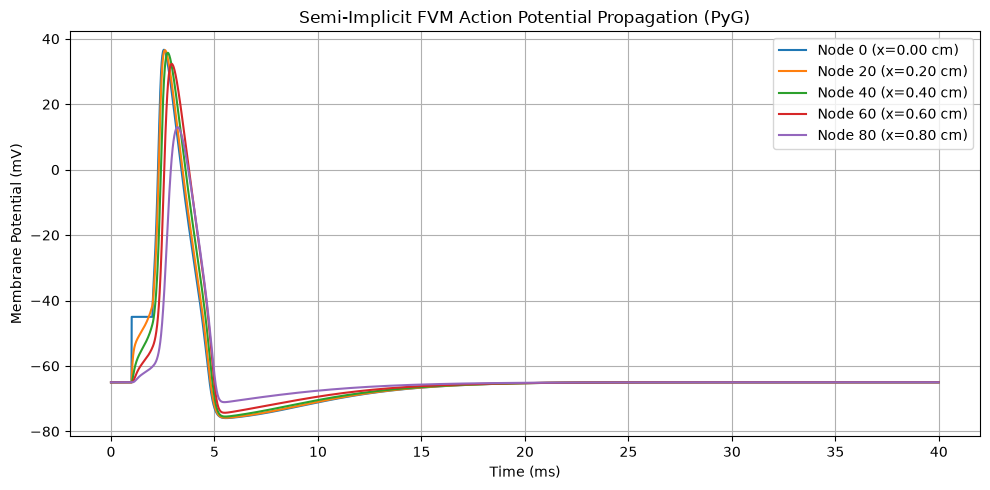

In [4]:
# Plotting Action Potential Propagation
plt.figure(figsize=(10, 5))
for node in [0, 20, 40, 60, 80]:
    plt.plot(time_track, history_V[node], label=f'Node {node} (x={node*dx:.2f} cm)')
plt.title("Semi-Implicit FVM Action Potential Propagation (PyG)")
plt.xlabel("Time (ms)")
plt.ylabel("Membrane Potential (mV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

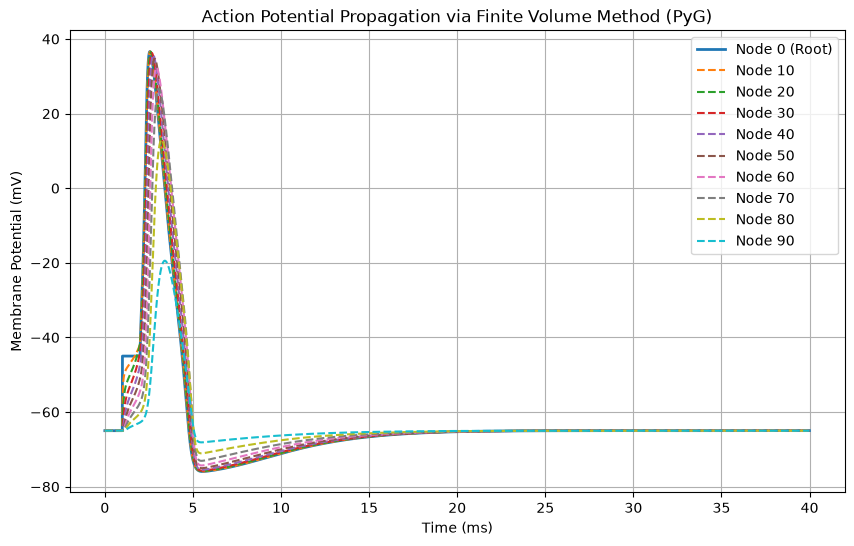

In [5]:
## Visualization of voltage propogation
plt.figure(figsize=(10, 6))

plt.plot(time_track, history_V[0], label='Node 0 (Root)', linewidth=2)
for v in range(10, 100, 10):
    plt.plot(time_track, history_V[v], label=f'Node {v}', linestyle='--')

plt.title("Action Potential Propagation via Finite Volume Method (PyG)")
plt.xlabel("Time (ms)")
plt.ylabel("Membrane Potential (mV)")
plt.legend()
plt.grid(True)
plt.show()


In [6]:
## Ionic current densities

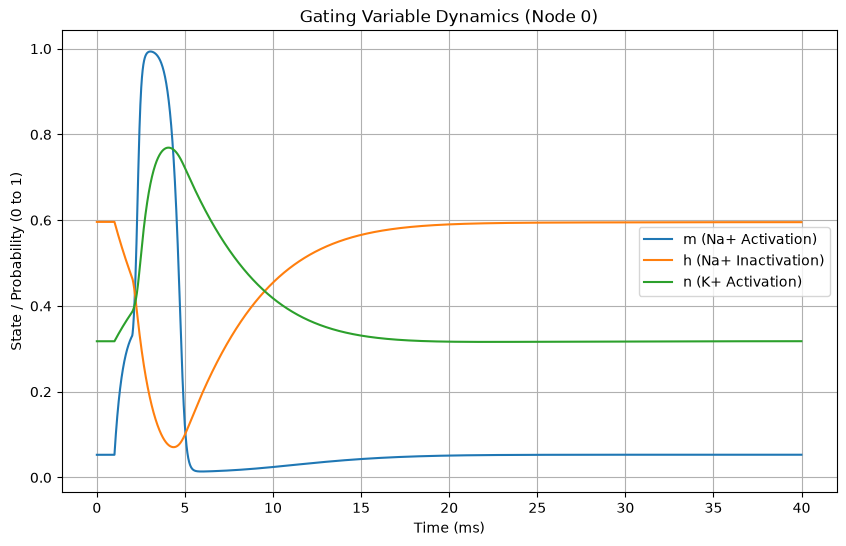

In [7]:
## Gating variables at root:


# 8. Plotting Gating Variables
# Extract m, h, and n traces specifically for Node 0
node_idx = 0
m_trace = [state[0] for state in history_gating_vars[node_idx]]
h_trace = [state[1] for state in history_gating_vars[node_idx]]
n_trace = [state[2] for state in history_gating_vars[node_idx]]

plt.figure(figsize=(10, 6))
plt.plot(time_track, m_trace, label='m (Na+ Activation)')
plt.plot(time_track, h_trace, label='h (Na+ Inactivation)')
plt.plot(time_track, n_trace, label='n (K+ Activation)')

plt.title(f"Gating Variable Dynamics (Node {node_idx})")
plt.xlabel("Time (ms)")
plt.ylabel("State / Probability (0 to 1)")
plt.legend(loc='center right')
plt.grid(True)
plt.show()


In [8]:
## Refractory Period